# 1. Modeling and Simulation

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

This book is about modeling and simulating physical systems. Before we can build any models, it’ll help to have a high-level understanding of what a model is. We’ll also need to familiarize ourselves with the tools we use to build them. In this chapter, we’ll look at the modeling process and introduce MATLAB, the programming language we’ll use to represent models and run simulations. At the end of the chapter you’ll find exercises you can use to test your knowledge.

## Modeling

When I say “modeling,” I’m talking about something like Figure 1.1. In the lower-left corner of the figure is the *system*, something in the real world we’re interested in. Often, it’s something complicated, so we have to decide which details can be left out; removing details is called *abstraction*.

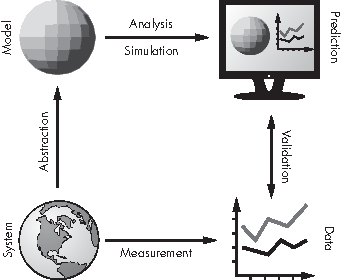

*Figure 1.1: The modeling process*

The result of abstraction is a *model*, shown in the upper left; a model is a description of the system that includes only the features we think are essential. A model can be represented in the form of diagrams and equations, which can be used for mathematical analysis. It can also be implemented in the form of a computer program, which can run simulations.

The result of analysis and simulation might be a prediction about what the system will do, an explanation of why it behaves the way it does, or a specific design engineered to satisfy a requirement or optimize performance.

We can validate predictions and test designs by taking measurements from the real world and comparing the data we get with the results from analysis and simulation.

For any physical system there are many possible models, each one including and excluding different features or including different levels of detail. The goal of the modeling process is to find the model best suited to its purpose (prediction, explanation, or design).

Sometimes the best model is the most detailed. If we include more features, the model is more realistic, and we expect its predictions to be more accurate. But often a simpler model is better. If we include only the essential features and leave out the rest, we get models that are easier to work with, and the explanations they provide can be clearer and more compelling.

As an example, suppose someone asked you why the orbit of the Earth is nearly elliptical. If you model the Earth and Sun as point masses (ignoring their actual size), compute the gravitational force between them using Newton’s law of universal gravitation, and compute the resulting orbit using Newton’s laws of motion, you can show that the result is an ellipse.

Of course, the actual orbit of Earth is not a perfect ellipse, because of the gravitational forces of the Moon, Jupiter, and other objects in the solar system, and because Newton’s laws of motion are only approximately true (they don’t take into account relativistic effects).

But adding these features to the model would not improve the explanation; more detail would only be a distraction from the fundamental cause. However, if the goal is to predict the position of the Earth with great precision, including more details might be necessary.

Choosing the best model depends on what the model is for. It is usually a good idea to start with a simple model, even if it’s likely to be too simple, and test whether it’s good enough for its purpose. Then you can add features gradually, starting with the ones you expect to be most essential. This process is called *iterative modeling*.

Comparing the results of successive models provides a form of *internal validation* so you can catch conceptual, mathematical, and software errors. And by adding and removing features, you can tell which ones have the biggest effect on the results, and which can be ignored.

Comparing results with data from the real world provides *external validation*, which is generally the strongest test.

Figure 1.1 shows that models can be used for both analysis and simulation; in this book we will do some analysis, but the focus is on simulation. And the tool we will use to build simulations is MATLAB. So let’s get started.

## A Glorified Calculator

MATLAB is a programming language with features that support modeling and simulation. It has a lot of features, so it can seem overwhelming, but at heart MATLAB is a glorified calculator. When you start MATLAB you should see a window entitled MATLAB that contains smaller windows entitled Current Folder, Command Window, and Workspace. In Octave, Current Folder is called File Browser.

### The Interpreter

The Command Window runs the *interpreter*, which allows you to enter *commands*; once entered, the interpreter executes the command and prints the result. Initially, the Command Window contains a welcome message with information about the version of the software you’re running, followed by a *prompt*, which looks like this:

```
>>
```

The `>>` symbol prompts you to enter a command. The simplest kind of command is a mathematical *expression*, like `2 + 1`. If you type an expression and then press (or ), MATLAB *evaluates* the expression and prints the result.

In [ ]:
2 + 1

Just to be clear: in this example, MATLAB displayed `>>`; I typed **`2 + 1`** and then hit , and MATLAB displayed `ans = 3`.

In this expression, the plus sign is an *operator* and the numbers `2` and `1` are *operands*. An expression can contain any number of operators and operands. You don’t have to put spaces between them; some people do and some people don’t. Here’s an example with no spaces:

In [ ]:
1+2+3+4+5+6+7+8+9

Speaking of spaces, you might have noticed that MATLAB puts a blank line between `ans =` and the result. In my examples I’ll leave it out to save room.

The other arithmetic operators are pretty much what you would expect. Subtraction is denoted by a minus sign (`-`), multiplication is designated by an asterisk (`*`), division is denoted by a forward slash (`/`).

In [ ]:
2*3 - 4/5

Another common operator is exponentiation, which uses the `^` symbol, sometimes called “caret” or “hat.” So, 2 raised to the 16th power is

In [ ]:
2^16

The order of operations is what you would expect from basic algebra: exponentiation happens before multiplication and division, and multiplication and division happen before addition and subtraction. If you want to override the order of operations, you can use parentheses.

In [ ]:
2 * (3-4) / 5

When I added the parentheses, I removed some spaces to make the grouping of operands clearer to a human reader. This is the first of many style guidelines I will recommend for making your programs easier to read. Style doesn’t change what the program does; the MATLAB interpreter doesn’t check for style. But human readers do, and the most important human who will read your code is you.

And that brings us to the First Theorem of Debugging:

> Readable code is debuggable code.

It’s worth spending time to make your code pretty; it will save you time debugging!

### Math Functions

MATLAB knows how to compute pretty much every math function you’ve heard of. For example, it knows all the trigonometric functions—here’s how you use them:

In [ ]:
sin(1)

This command is an example of a *function call*. The name of the function is `sin`, which is the usual abbreviation for the trigonometric sine. The value in parentheses is called the *argument*.

The trig functions `sin`, `cos`, and `tan`—among many others—work in radians, so the argument in the example is interpreted as 1 radian. MATLAB also provides trig functions that work in degrees: `sind`, `cosd`, and `tand`.

Some functions take more than one argument, in which case the arguments are separated by commas. For example, `atan2` computes the inverse tangent, which is the angle in radians between the positive x-axis and the point with the given x- and y-coordinates.

In [ ]:
atan2(1,1)

If that bit of trigonometry isn’t familiar to you, don’t worry about it. It’s just an example of a function with multiple arguments.

MATLAB also provides exponential functions, like `exp`, which computes $e$ raised to the given power. So `exp(1)` is just $e$:

In [ ]:
exp(1)

The inverse of `exp` is `log`, which computes the logarithm base $e$:

In [ ]:
log(exp(3))

This example also demonstrates that function calls can be *nested*; that is, you can use the result from one function as an argument for another.

More generally, you can use a function call as an operand in an expression.

In [ ]:
sqrt(sin(0.5)^2 + cos(0.5)^2)

As you probably guessed, `sqrt` computes the square root.

There are lots of other math functions, but this isn’t meant to be a reference manual. To learn about other functions, you should read the documentation.

## Variables

Of course, MATLAB is good for more than just evaluating expressions. One of the features that makes MATLAB more powerful than a calculator is the ability to give a name to a value. A named value is called a *variable*.

MATLAB comes with a few predefined variables. For example, the name `pi` refers to the mathematical quantity $\pi$, which is approximately this:

In [ ]:
pi

And if you do anything with complex numbers, you might find it convenient that both `i` and `j` are predefined as the square root of $-1$.

You can use a variable name anywhere you can use a number—for example, as an operand in an expression,

In [ ]:
pi * 3^2

or as an argument to a function:

In [ ]:
sin(pi/2)

Whenever you evaluate an expression, MATLAB assigns the result to a variable named `ans`. You can use `ans` in a subsequent calculation as shorthand for “the value of the previous expression.”

In [ ]:
3^2 + 4^2
sqrt(ans)

But keep in mind that the value of `ans` changes every time you evaluate an expression.

### Assignment Statements

You can create your own variables, and give them values, with an *assignment statement*. The assignment operator is the equals sign (`=`), used like so:

In [ ]:
x = 6 * 7

This example creates a new variable named `x` and assigns it the value of the expression `6 * 7`. MATLAB responds with the variable name and the computed value.

There are a few rules when assigning variables a value. In every assignment statement, the left side has to be a legal variable name. The right side can be any expression, including function calls.

Almost any sequence of lower- and uppercase letters is a legal variable name. Some punctuation is also legal, but the underscore (`_`) is the only commonly used non-letter. Numbers are fine, but not at the beginning. Spaces are not allowed. Variable names are *case sensitive*, so `x` and `X` are different variables.

Let’s look at some examples of assignment statements.

In [ ]:
fibonacci0 = 1;
LENGTH = 10;
first_name = 'bob'

The first two examples demonstrate the use of the semicolon, which suppresses the output from a command. In this case MATLAB creates the variables and assigns them values but displays nothing.

The third example demonstrates that not everything in MATLAB is a number. A sequence of characters in single quotes is a *string*.

Although `i`, `j`, and `pi` are predefined, you are free to reassign them. It’s common to use `i` and `j` for other purposes, but it’s rare to assign a different value to `pi`.

### Variables in the Workspace

When you create a new variable, it appears in the Workspace window and is added to the *workspace*, which is a set of variables and their values.

The `who` command prints the names of the variables in the workspace:

In [ ]:
x = 5;
y = 7;
z = 9;
who

The `clear` command removes specified variables from the workspace:

In [ ]:
clear x
who

But be careful: if you don’t specify any variables, `clear` removes them all.

To display the value of a variable, you can use the `disp` function:

In [ ]:
disp(z)

but it’s easier to just type the variable name:

In [ ]:
z

Now that you’ve seen how to use them, let’s take a step back and think about why we’d use variables.

### Why Variables?

There are a number of reasons to use variables. A big one is to avoid recomputing a value you use repeatedly. For example, if your computation uses $e$ frequently, you might want to compute it once and save the result.

In [ ]:
e = exp(1)

Variables also make the connection between the code and the underlying mathematics more apparent. If you’re computing the area of a circle, you might want to use a variable named `r`:

In [ ]:
r = 3
area = pi * r^2

That way, your code resembles the familiar formula $a = \pi r^2$.

You might also use a variable to break a long computation into a sequence of steps. Suppose you’re evaluating a big, hairy expression like this:

```
p = ((x - theta) * sqrt(2 * pi) * sigma)^-1 * ...
exp(-1/2 * (log(x - theta) - zeta)^2 / sigma^2)
```

You can use an ellipsis to break the expression into multiple lines. Just enter `...` at the end of the first line and continue on to the next.

But often it’s better to break the computation into a sequence of steps and assign intermediate results to variables:

```
shiftx = x - theta
denom = shiftx * sqrt(2 * pi) * sigma
temp = (log(shiftx) - zeta) / sigma
exponent = -1/2 * temp^2
p = exp(exponent) / denom
```

The names of the intermediate variables explain their role in the computation: `shiftx` is the value of `x` shifted by `theta`, it should be no surprise that `exponent` is the argument of `exp`, and `denom` ends up in the denominator. Choosing informative names makes the code easier to read and understand, which makes it easier to debug.

## Errors

Every error is a learning opportunity. Whenever you learn a new feature, you should try to make as many errors as possible, as soon as possible. When you make deliberate errors, you see what the error messages are. Later, when you make accidental errors, you’ll know what the messages mean.

Let’s look at some common errors. A big one for beginners is leaving out the `*` for multiplication, as in this example:

```
area = pi r^2
```

This code should produce the following error message:

```
 area = pi r^2
           |
Error: Invalid expression. Check for missing multiplication
operator, missing or unbalanced delimiters, or other syntax
error. To construct matrices, use brackets instead of parentheses.
```

In Octave, it is:

```
error: syntax error
```

The message indicates that the expression is invalid and suggests several things that might be wrong. In this case, one of its guesses is right: we’re missing a multiplication operator.

Another common error is to leave out the parentheses around the arguments of a function. For example, in math notation it’s common to write something like $\sin \pi$, but in MATLAB if you write

```
sin pi
```

you should get the following error message:

In MATLAB, the error message is:

```
Undefined function 'sin' for input arguments of type 'char'.
```

In Octave, it is:

```
error: sin: argument must be numeric
```

The problem is that when you leave out the parentheses, MATLAB treats the argument as a string of characters (which have type `’char’`). In this case the error message is helpful, but in other cases the results can be baffling. For example, if you call `abs`, which computes absolute values, and forget the parentheses, you get a surprising result:

In [ ]:
abs pi

I won’t explain this result; for now, I’ll just suggest that you should *always* put parentheses around arguments.

Here’s another common error. If you were translating the mathematical expression

$$\frac{1}{2 \sqrt \pi}$$

into MATLAB, you might be tempted to write this:

In [ ]:
1 / 2 * sqrt(pi)

But that would be wrong because of the order of operations. Division and multiplication are evaluated from left to right, so this expression would multiply `1/2` by `sqrt(pi)`.

To keep `sqrt(pi)` in the denominator, you could use parentheses,

In [ ]:
1 / (2 * sqrt(pi))

or make the division explicit,

In [ ]:
1 / 2 / sqrt(pi)

The last two examples bring us to the Second Theorem of Debugging:

> The only thing worse than getting an error message is *not* getting an error message.

Beginning programmers often hate error messages and do everything they can to make the messages go away. Experienced programmers know that error messages are your friend. They can be hard to understand, and even misleading, but it’s worth the effort to understand them.

## Documentation

MATLAB comes with two forms of documentation, `help` and `doc`.

The `help` command works in the Command Window; just enter **`help`** followed by the name of a command.

```
>> help sin
```

*In the browser version of Octave, `help` doesn't work for built-in functions like `sin`; it works in MATLAB and desktop Octave.*

You should see output like this:

```
sin    Sine of argument in radians.
   sin(X) is the sine of the elements of X.

   See also asin, sind, sinpi.
```

Some documentation uses vocabulary we haven’t covered yet. For example, `the elements of X` might not make sense until we get to vectors and matrices a few chapters from now.

The `doc` pages are usually better. If you enter `doc sin`, a browser window appears with more detailed information about the function, including examples of how to use it. The examples often use vectors and matrices, so they may not make sense yet, but you can get a preview of what’s coming.

## Chapter Review

This chapter provided an overview of the modeling process, including abstraction, analysis and simulation, measurement, and validation.

It also introduced MATLAB, the programming language we’ll use to write simulations. So far, we’ve seen variables and values, arithmetic operations, and mathematical functions.

Here are a few terms from this chapter you might want to remember.

The *interpreter* is the program that reads and executes MATLAB or Octave code. It prints a *prompt* to indicate that it’s waiting for you to type a *command*, which is a line of code executed by the interpreter.

An *operator* is a symbol, like `*` or `+`, that represents a mathematical operation. An *operand* is a number or variable that appears in an expression along with operators. An *expression* is a sequence of operands and operators that specifies a mathematical computation and yields a value.

A *function* is a named computation; for example, `log10` is the name of a function that computes logarithms in base 10. A *function call* is a command that causes a function to execute and compute a result. An *argument* is an expression that appears in a function call to specify the value the function operates on.

A *variable* is a named value. An *assignment statement* is a command that creates a new variable (if necessary) and gives it a value. A *workspace* is a set of variables and their values.

Finally, a *string* is a value that consists of a sequence of characters (as opposed to a number).

In the next chapter, you’ll start writing longer programs and learn about floating-point numbers.

## Exercises

Before you go on, you might want to work on the following exercises.

**Exercise.**

You might have heard that a penny dropped from the top of the Empire State Building would be going so fast when it hit the pavement that it would be embedded in the concrete or that if it hit a person it would break their skull.

We can test this myth by making and analyzing a model. To get started, we’ll assume that the effect of air resistance is small. This will turn out to be a bad assumption, but bear with me.

If air resistance is negligible, the primary force acting on the penny is gravity, which causes the penny to accelerate downward.

If the initial velocity is 0, the velocity after $t$ seconds is $a t$, and the distance the penny has dropped is

$$h = a t^2 / 2$$

Using algebra, we can solve for $t$:

$$t = \sqrt{ 2 h / a}$$

Plugging in the acceleration of gravity, $a = 9.8 m/s\squared$, and the height of the Empire State Building, $h = 381 m$, we get $t = 8.8 s$. Then, computing $v = a t$ we get a velocity on impact of $86 m/s$, which is about 190 miles per hour. That sounds like it could hurt.

Use MATLAB to perform these computations, and check that you get the same result.

**Exercise.** The result in the previous exercise is not accurate because it ignores air resistance. In reality, once the penny gets to about 18 m/s, the upward force of air resistance equals the downward force of gravity, so the penny stops accelerating. After that, it doesn’t matter how far the penny falls; it hits the sidewalk at about 18 m/s, much less than 86 m/s.

As an exercise, compute the time it takes for the penny to reach the sidewalk if we assume that it accelerates with constant acceleration $a = 9.8 m/s\squared$ until it reaches terminal velocity, then falls with constant velocity until it hits the sidewalk.

The result you get is not exact, but it’s a pretty good approximation.

In [ ]:
% Exercise 1.1: your solution here


In [ ]:
% Exercise 1.2: your solution here
